# 09 – Self-Supervised Učení reprezentací: 1D Autoencoder / Ortogonální latentní báze
Nalezení 16-dimenzionální komprimované latentní báze $z \in \mathbb{R}^{16}$ a rekonstrukční chyby MSE pro detekci anomálií bez učitele.

Metriky separability (Self-Supervised Latent Basis): {'method_name': 'autoencoder', 'fdr_score': 0.0865, 'silhouette_score': -0.0396, 'davies_bouldin_score': 15.2022, 'mutual_info_mean': 0.2317, 'anova_f_mean': 107.2741, 'separability_by_phenomenon': {'static_load_fdr': 0.0326, 'thermal_fdr': 0.0873, 'transition_edge_fdr': 0.0011}}


,measurement_code,inherited_label,ae_reconstruction_mse,ae_latent_norm,ae_z00,ae_z01
0,0773,klid_pred_teplotou,1.127315e-08,5.353383,0.129319,0.000120
1,0773,klid_pred_teplotou,1.185915e-08,7.038884,0.129291,0.000133
2,0773,klid_pred_teplotou,1.276200e-08,6.813137,0.129297,0.000144
3,0773,klid_pred_teplotou,1.131857e-08,8.938971,0.129373,0.000191
4,0773,klid_pred_teplotou,9.244027e-09,9.564243,0.129450,0.000219
5,0773,klid_pred_teplotou,8.677168e-09,9.147364,0.129580,0.000178
6,0773,klid_pred_teplotou,8.989308e-09,8.773056,0.129611,0.000149
7,0773,klid_pred_teplotou,1.025782e-08,9.715905,0.129566,0.000177
8,0773,klid_pred_teplotou,1.123062e-08,9.204940,0.129577,0.000177
9,0773,klid_pred_teplotou,1.116019e-08,9.005857,0.129600,0.000194


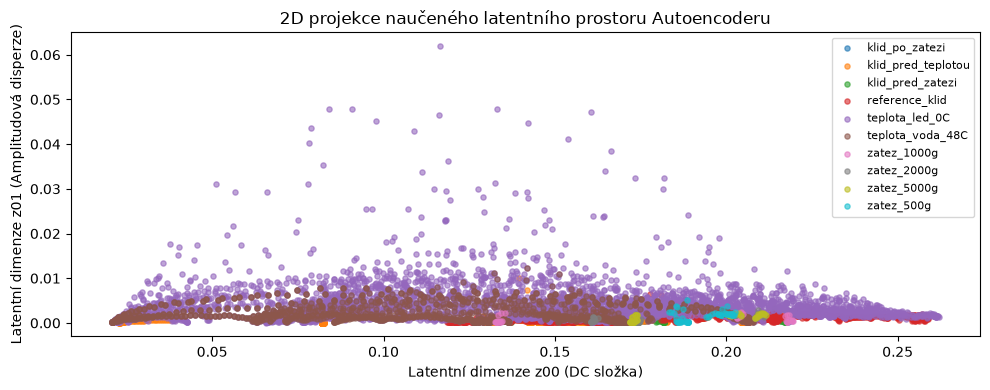

In [1]:
import matplotlib.pyplot as plt
from icaros.analysis.runner import load_windows_with_signals, run_single_silver_method
from icaros.db.s3 import read_parquet_from_s3

df_win, signals, fs = load_windows_with_signals("win128_stride32")
res = run_single_silver_method("autoencoder", df_win, signals, fs, "win128_stride32")
print("Metriky separability (Self-Supervised Latent Basis):", {k: v for k, v in res.items() if k != "s3_uri"})
df_ae = read_parquet_from_s3(res["s3_uri"])
display(df_ae[["measurement_code", "inherited_label", "ae_reconstruction_mse", "ae_latent_norm", "ae_z00", "ae_z01"]].head(12))

fig, ax = plt.subplots(figsize=(10, 4))
for lbl, grp in df_ae.groupby("inherited_label"):
    ax.scatter(grp["ae_z00"], grp["ae_z01"], s=14, alpha=0.6, label=lbl)
ax.set_xlabel("Latentní dimenze z00 (DC složka)")
ax.set_ylabel("Latentní dimenze z01 (Amplitudová disperze)")
ax.set_title("2D projekce naučeného latentního prostoru Autoencoderu")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()